# Phase 6b: Brief Requirements for Modelling (Linear Baseline, 10-SKU Evaluation, Stock-out Prediction)

**Project:** FMCG Global Demand Planning Capstone
**Inputs:** `data/fmcg_features.parquet` (Phase 4), `data/fmcg_clean.csv`, `data/abc_xyz_segments.csv`, `reports/tuning_results.csv` (Phase 5)
**Outputs:** tables and figures in `reports/`

This notebook closes the remaining modelling requirements of the course brief:

| Brief requirement | Section |
|---|---|
| Month-start / month-end calendar flags | 2 |
| **Linear Regression baseline** with `StandardScaler` (fit on train only) and one-hot encoding | 3 |
| Ensemble vs linear comparison | 4 |
| **Forecast for 10 representative SKUs** across segments (AX, BY, CZ ...) with **MAE, RMSE, MAPE** | 5 |
| **Stock-out prediction** with Precision, Recall and F1 | 6 |

The time split is the same as in Phases 4-5, so every number is comparable: **train** up to 2022-12-31, **validation** Jan-Jun 2023, **test** Jul-Dec 2023.

## 1. Setup and load

In [18]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_recall_curve, average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score, confusion_matrix)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (10, 4)
os.makedirs("../reports/figures", exist_ok=True)
SEED = 42

def savefig(name):
    plt.savefig(f"../reports/figures/{name}.png", dpi=150, bbox_inches="tight")

try:
    feats = pd.read_parquet("../data/fmcg_features.parquet")
except Exception:
    feats = pd.read_csv("../data/fmcg_features.csv", parse_dates=["date"])

target = "units_sold"
id_cols = ["series_id", "date"]
base_features = [c for c in feats.columns if c not in id_cols + [target]]   # the Phase 4/5 feature set
print("Rows:", f"{len(feats):,}", "| Phase 4/5 features:", len(base_features))

Rows: 1,069,850 | Phase 4/5 features: 31


### Extra information from the raw data
Two things are added from `fmcg_clean.csv`:
- `so_today`: was there a stock-out on that day. **Used only as the target in section 6 and as an evaluation filter**, never as a demand-model input.
- Yesterday's stock on hand (`soh_lag1`) and lead time (`lt_lag1`), built with a one-day shift so they are known before the day starts. They are used only in the stock-out model.

In [2]:
raw = pd.read_csv("../data/fmcg_clean.csv",
                  usecols=["store_id", "sku_id", "date", "sku_name", "stock_on_hand",
                           "lead_time_days", "stock_out_flag"],
                  parse_dates=["date"])
raw["series_id"] = raw["store_id"] + "_" + raw["sku_id"]
raw = raw.sort_values(["series_id", "date"]).reset_index(drop=True)
raw["soh_lag1"] = raw.groupby("series_id")["stock_on_hand"].shift(1)
raw["lt_lag1"] = raw.groupby("series_id")["lead_time_days"].shift(1)

feats = feats.merge(
    raw[["series_id", "date", "soh_lag1", "lt_lag1", "stock_out_flag"]]
       .rename(columns={"stock_out_flag": "so_today"}),
    on=["series_id", "date"], how="left")
# Days of cover: how many days of recent demand yesterday's stock would last.
feats["cover_days"] = feats["soh_lag1"] / feats["roll_mean_7"].replace(0, np.nan)
print("Rows after merge:", f"{len(feats):,}", "| missing so_today:", feats["so_today"].isna().sum())

Rows after merge: 1,069,850 | missing so_today: 0


## 2. Month-start and month-end flags
The brief asks for flags for **holidays, weekends and month-start/month-end effects**. Holidays and weekends already exist; we add `is_month_start` and `is_month_end` (first and last calendar day of the month).

First a descriptive check: units relative to each series' own average, on flagged vs other days.

In [3]:
feats["is_month_start"] = feats["date"].dt.is_month_start.astype(int)
feats["is_month_end"] = feats["date"].dt.is_month_end.astype(int)

feats["rel_units"] = feats[target] / feats.groupby("series_id")[target].transform("mean")
for flag in ["is_month_start", "is_month_end"]:
    t = feats.groupby(flag)["rel_units"].agg(["mean", "count"])
    t["share_of_days_%"] = t["count"] / t["count"].sum() * 100
    print(f"\nRelative units (1.00 = series average) by {flag}:")
    print(t.round(3).to_string())


Relative units (1.00 = series average) by is_month_start:
                mean    count  share_of_days_%
is_month_start                                
0              1.000  1034690           96.714
1              0.991    35160            3.286

Relative units (1.00 = series average) by is_month_end:
              mean    count  share_of_days_%
is_month_end                                
0            1.000  1033686           96.620
1            0.999    36164            3.380


## 3. Splits and metrics

In [4]:
train_mask = (feats["date"] <= "2022-12-31").values
valid_mask = ((feats["date"] >= "2023-01-01") & (feats["date"] <= "2023-06-30")).values
test_mask  = (feats["date"] >= "2023-07-01").values
trainvalid_mask = train_mask | valid_mask

for name, m in [("train", train_mask), ("validation", valid_mask), ("test", test_mask)]:
    d = feats.loc[m, "date"]
    print(f"{name:11s} {d.min().date()} to {d.max().date()}  rows: {m.sum():,}")

def metrics(y, p, mask=None):
    """MAE/RMSE in units; MAPE on days with sales > 0 (MAPE is undefined at zero); WAPE = total abs error / total actual."""
    y = np.asarray(y, dtype=float)
    p = np.clip(np.asarray(p, dtype=float), 0, None)
    if mask is not None:
        y, p = y[mask], p[mask]
    nz = y > 0
    return {"MAE": np.abs(y - p).mean(),
            "RMSE": np.sqrt(((y - p) ** 2).mean()),
            "MAPE_%": (np.abs(y[nz] - p[nz]) / y[nz]).mean() * 100,
            "WAPE": np.abs(y - p).sum() / y.sum()}

train       2021-01-31 to 2022-12-31  rows: 703,390
validation  2023-01-01 to 2023-06-30  rows: 181,724
test        2023-07-01 to 2023-12-31  rows: 184,736


## 4. Linear Regression baseline
The brief asks for Linear Regression as a **performance floor**. Linear models need numbers on comparable scales and cannot use arbitrary integer codes, so the preprocessing differs from the tree models:

- **Scaling:** `StandardScaler` (subtract the mean, divide by the std) on the numerical features. **It is fitted on the training period only** and then applied to validation and test, so no information from the future leaks in.
- **One-hot encoding** for channel, category, weekday and month (one 0/1 column per level, dropping one level).
- **Label-encoded** country, as the brief specifies. This treats countries as ordered numbers, which is questionable for a linear model; we keep it for fidelity to the brief and note the limit.
- High-cardinality codes (store, SKU, brand, subcategory) are left out: as plain numbers they would be meaningless to a linear model.
- Binary flags (promo, holiday, weekend, month-start, month-end) stay as 0/1.

In [5]:
num_cols = ["lag_1", "lag_7", "lag_14", "lag_30", "roll_mean_7", "roll_std_7", "roll_mean_30", "roll_std_30",
            "promo_last7", "stockout_last7", "discount_pct", "list_price", "temperature", "rain_mm",
            "day", "weekofyear", "country_code", "abc_code", "xyz_rel_code"]
bin_cols = ["promo_flag", "is_holiday", "is_weekend", "is_month_start", "is_month_end", "stockout_lag1"]
onehot = [("channel_code", "ch"), ("category_code", "cat"), ("weekday", "wd"), ("month", "mo")]

X_all = feats[num_cols + bin_cols].astype(float).copy()
for col, prefix in onehot:
    X_all = pd.concat([X_all, pd.get_dummies(feats[col], prefix=prefix, drop_first=True).astype(float)], axis=1)
print("Design matrix:", X_all.shape, "| numerical (scaled):", len(num_cols))

def fit_linear(fit_mask, pred_mask):
    scaler = StandardScaler().fit(X_all.loc[fit_mask, num_cols])      # statistics from the fitting period only
    def prep(m):
        Xm = X_all.loc[m].copy()
        Xm[num_cols] = scaler.transform(Xm[num_cols])
        return Xm
    model = LinearRegression().fit(prep(fit_mask), feats.loc[fit_mask, target])
    return model, model.predict(prep(pred_mask))

lr_val_model, lr_val_pred = fit_linear(train_mask, valid_mask)
print("Linear Regression, validation:", {k: round(v, 3) for k, v in metrics(feats.loc[valid_mask, target], lr_val_pred).items()})
print("Baseline roll_mean_30, validation:", {k: round(v, 3) for k, v in metrics(feats.loc[valid_mask, target], feats.loc[valid_mask, "roll_mean_30"]).items()})

Design matrix: (1069850, 49) | numerical (scaled): 19
Linear Regression, validation: {'MAE': np.float64(16.727), 'RMSE': np.float64(24.873), 'MAPE_%': np.float64(60.14), 'WAPE': np.float64(0.289)}
Baseline roll_mean_30, validation: {'MAE': np.float64(18.107), 'RMSE': np.float64(28.318), 'MAPE_%': np.float64(61.105), 'WAPE': np.float64(0.313)}


In [6]:
coefs = pd.Series(lr_val_model.coef_, index=X_all.columns)
print("Largest coefficients (numerical ones are per 1 std change; dummies are per level):")
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12).round(2).to_string())

Largest coefficients (numerical ones are per 1 std change; dummies are per level):
promo_flag     26.880
roll_mean_30   24.390
roll_mean_7     9.350
is_weekend      7.560
discount_pct    5.900
mo_6            4.950
mo_11           4.530
cat_2          -4.160
promo_last7    -4.130
mo_12           3.950
wd_5            3.900
cat_1          -3.730


## 5. Final test: linear baseline vs boosting
All models predict the **test period (Jul-Dec 2023)**, refit on train + validation. We compare:
1. Naive baseline (`roll_mean_30`)
2. Linear Regression (scaled, one-hot)
3. LightGBM with the Phase 5 features and the best settings from Phase 5 (`reports/tuning_results.csv`)
4. The same LightGBM **plus the month-start / month-end flags**, to see whether the new flags help

In [7]:
tune = pd.read_csv("../reports/tuning_results.csv")
best = tune[tune["family"] == "LightGBM"].iloc[0]       # best LightGBM row, as selected in Phase 5
lgb_params = dict(n_estimators=int(best["trees"]), learning_rate=0.05, num_leaves=int(best["num_leaves"]),
                  objective=best["objective"], subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                  min_child_samples=50, random_state=SEED, n_jobs=-1, verbose=-1)
print("LightGBM settings from Phase 5:", {k: lgb_params[k] for k in ["objective", "num_leaves", "n_estimators"]})

test_df = feats.loc[test_mask].copy()
fv = feats.loc[trainvalid_mask]

_, lr_test_pred = fit_linear(trainvalid_mask, test_mask)

m1 = lgb.LGBMRegressor(**lgb_params).fit(fv[base_features], fv[target])
lgb_pred = m1.predict(test_df[base_features])

feats_plus = base_features + ["is_month_start", "is_month_end"]
m2 = lgb.LGBMRegressor(**lgb_params).fit(fv[feats_plus], fv[target])
lgb_plus_pred = m2.predict(test_df[feats_plus])

test_df["naive"] = test_df["roll_mean_30"]
test_df["linear"] = lr_test_pred
test_df["lightgbm"] = lgb_pred
test_df["lightgbm_flags"] = lgb_plus_pred
model_cols = ["naive", "linear", "lightgbm", "lightgbm_flags"]
labels = {"naive": "Naive roll_mean_30", "linear": "Linear Regression",
          "lightgbm": "LightGBM", "lightgbm_flags": "LightGBM + month flags"}

LightGBM settings from Phase 5: {'objective': 'poisson', 'num_leaves': 127, 'n_estimators': 699}


In [8]:
normal = (test_df["so_today"] == 0).values

rows = []
for c in model_cols:
    for view, mk in [("all days", None), ("non-stock-out days", normal)]:
        rows.append({"model": labels[c], "view": view, **metrics(test_df[target], test_df[c], mk)})
cmp = pd.DataFrame(rows)

for view in ["all days", "non-stock-out days"]:
    print(f"\nTEST SET (Jul-Dec 2023), {view}:")
    print(cmp[cmp["view"] == view].drop(columns="view").set_index("model").round(3).to_string())

cmp.to_csv("../reports/linear_vs_boosting_test.csv", index=False)


TEST SET (Jul-Dec 2023), all days:
                          MAE   RMSE  MAPE_%  WAPE
model                                             
Naive roll_mean_30     19.120 30.224  60.627 0.316
Linear Regression      17.595 26.574  59.801 0.291
LightGBM               16.154 24.677  55.226 0.267
LightGBM + month flags 16.153 24.666  55.202 0.267

TEST SET (Jul-Dec 2023), non-stock-out days:
                          MAE   RMSE  MAPE_%  WAPE
model                                             
Naive roll_mean_30     18.207 28.954  36.711 0.293
Linear Regression      16.629 24.962  36.474 0.268
LightGBM               15.147 22.819  31.877 0.244
LightGBM + month flags 15.146 22.815  31.868 0.244


## 6. Forecasting 10 representative series
The brief asks for **10 selected SKUs with diverse demand profiles** (for example 2 from AX, 2 from BY, 2 from CZ). We forecast at store-SKU level, so we pick 10 **store-SKU series**.

**Segments:** in Phase 2 every series was "X" on the absolute CV scale, so we use the **relative** XYZ classes (thirds by CV rank) saved as `segment_rel`. "Z" therefore means "relatively more variable", not erratic in an absolute sense.

**Selection rule (reproducible, no cherry-picking):** within each segment we take the series whose revenue is closest to that segment's median.

In [9]:
seg = pd.read_csv("../data/abc_xyz_segments.csv").set_index("series_id")
info = (raw.drop_duplicates("series_id").set_index("series_id")[["sku_name"]]
          .join(pd.read_csv("../data/fmcg_clean.csv", usecols=["store_id", "sku_id", "category", "channel", "country"])
                  .assign(series_id=lambda d: d["store_id"] + "_" + d["sku_id"])
                  .drop_duplicates("series_id").set_index("series_id")[["category", "channel", "country"]]))

PICKS = {"AX": 2, "AZ": 1, "BY": 2, "BZ": 1, "CX": 1, "CY": 1, "CZ": 2}   # 10 series in total
chosen = []
for code_, n in PICKS.items():
    cand = seg[seg["segment_rel"] == code_]
    med = cand["net_sales"].median()
    ids = (cand["net_sales"] - med).abs().sort_values().head(n).index
    chosen += [(code_, sid) for sid in ids]

picked = pd.DataFrame(chosen, columns=["segment", "series_id"]).set_index("series_id")
picked = picked.join(info).join(seg[["net_sales", "cv"]])
print(picked.round(3).to_string())

                  segment           sku_name       category      channel  country   net_sales    cv
series_id                                                                                          
STORE0003_SKU0060      AX        BrandF Milk          Dairy  Supermarket    Italy 702,337.500 0.131
STORE0007_SKU0060      AX        BrandF Milk          Dairy  Supermarket    Spain 702,418.500 0.124
STORE0003_SKU0001      AZ        BrandA Soda      Beverages  Supermarket    Italy 670,489.230 0.260
STORE0007_SKU0098      BY  BrandB Toothpaste  Personal Care  Supermarket    Spain 225,858.450 0.195
STORE0006_SKU0077      BY    BrandE Softener      Home Care  Hypermarket   France 225,704.970 0.176
STORE0009_SKU0011      BZ       BrandE Juice      Beverages   E-commerce    Spain 250,082.230 0.285
STORE0006_SKU0055      CX        BrandA Milk          Dairy  Hypermarket   France  72,462.600 0.136
STORE0010_SKU0086      CY     BrandB Shampoo  Personal Care   E-commerce    Italy  99,727.370 0.187


In [10]:
sel = test_df[test_df["series_id"].isin(picked.index)].copy()
sel["segment"] = sel["series_id"].map(picked["segment"])

rows = []
for sid, g in sel.groupby("series_id"):
    mk = (g["so_today"] == 0).values
    for c in model_cols:
        rows.append({"series_id": sid, "segment": picked.loc[sid, "segment"], "model": labels[c],
                     **metrics(g[target], g[c], mk)})
per_series = pd.DataFrame(rows)

for metric in ["MAE", "RMSE", "MAPE_%"]:
    print(f"\n{metric} by series (test period, non-stock-out days):")
    t = per_series.pivot_table(index=["segment", "series_id"], columns="model", values=metric)
    print(t[[labels[c] for c in model_cols]].round(2).to_string())

per_series.to_csv("../reports/ten_series_evaluation.csv", index=False)


MAE by series (test period, non-stock-out days):
model                      Naive roll_mean_30  Linear Regression  LightGBM  LightGBM + month flags
segment series_id                                                                                 
AX      STORE0003_SKU0060              13.010             12.270    12.130                  12.180
        STORE0007_SKU0060              11.280             10.620    10.560                  10.570
AZ      STORE0003_SKU0001              36.670             28.430    25.750                  25.280
BY      STORE0006_SKU0077              22.180             17.130    17.100                  17.100
        STORE0007_SKU0098              11.870             12.860     9.900                   9.890
BZ      STORE0009_SKU0011              10.230             11.040     6.660                   6.680
CX      STORE0006_SKU0055               4.480              5.140     4.210                   4.210
CY      STORE0010_SKU0086               2.990             1

In [11]:
# Pooled over the 10 series, and by segment.
mk_all = (sel["so_today"] == 0).values
print("Pooled over the 10 series (non-stock-out days):")
pooled = pd.DataFrame({labels[c]: metrics(sel[target], sel[c], mk_all) for c in model_cols}).T
print(pooled.round(3).to_string())

# How many days did the MAPE exclude because sales were zero?
nz_share = ((sel[target] == 0) & mk_all).sum() / mk_all.sum() * 100
print(f"\nZero-sales days among the non-stock-out days of these series (excluded from MAPE): {nz_share:.2f}%")

Pooled over the 10 series (non-stock-out days):
                          MAE   RMSE  MAPE_%  WAPE
Naive roll_mean_30     12.564 22.233  37.489 0.299
Linear Regression      12.230 18.936  44.133 0.291
LightGBM               10.061 16.118  31.604 0.239
LightGBM + month flags 10.021 15.962  31.604 0.238

Zero-sales days among the non-stock-out days of these series (excluded from MAPE): 0.06%


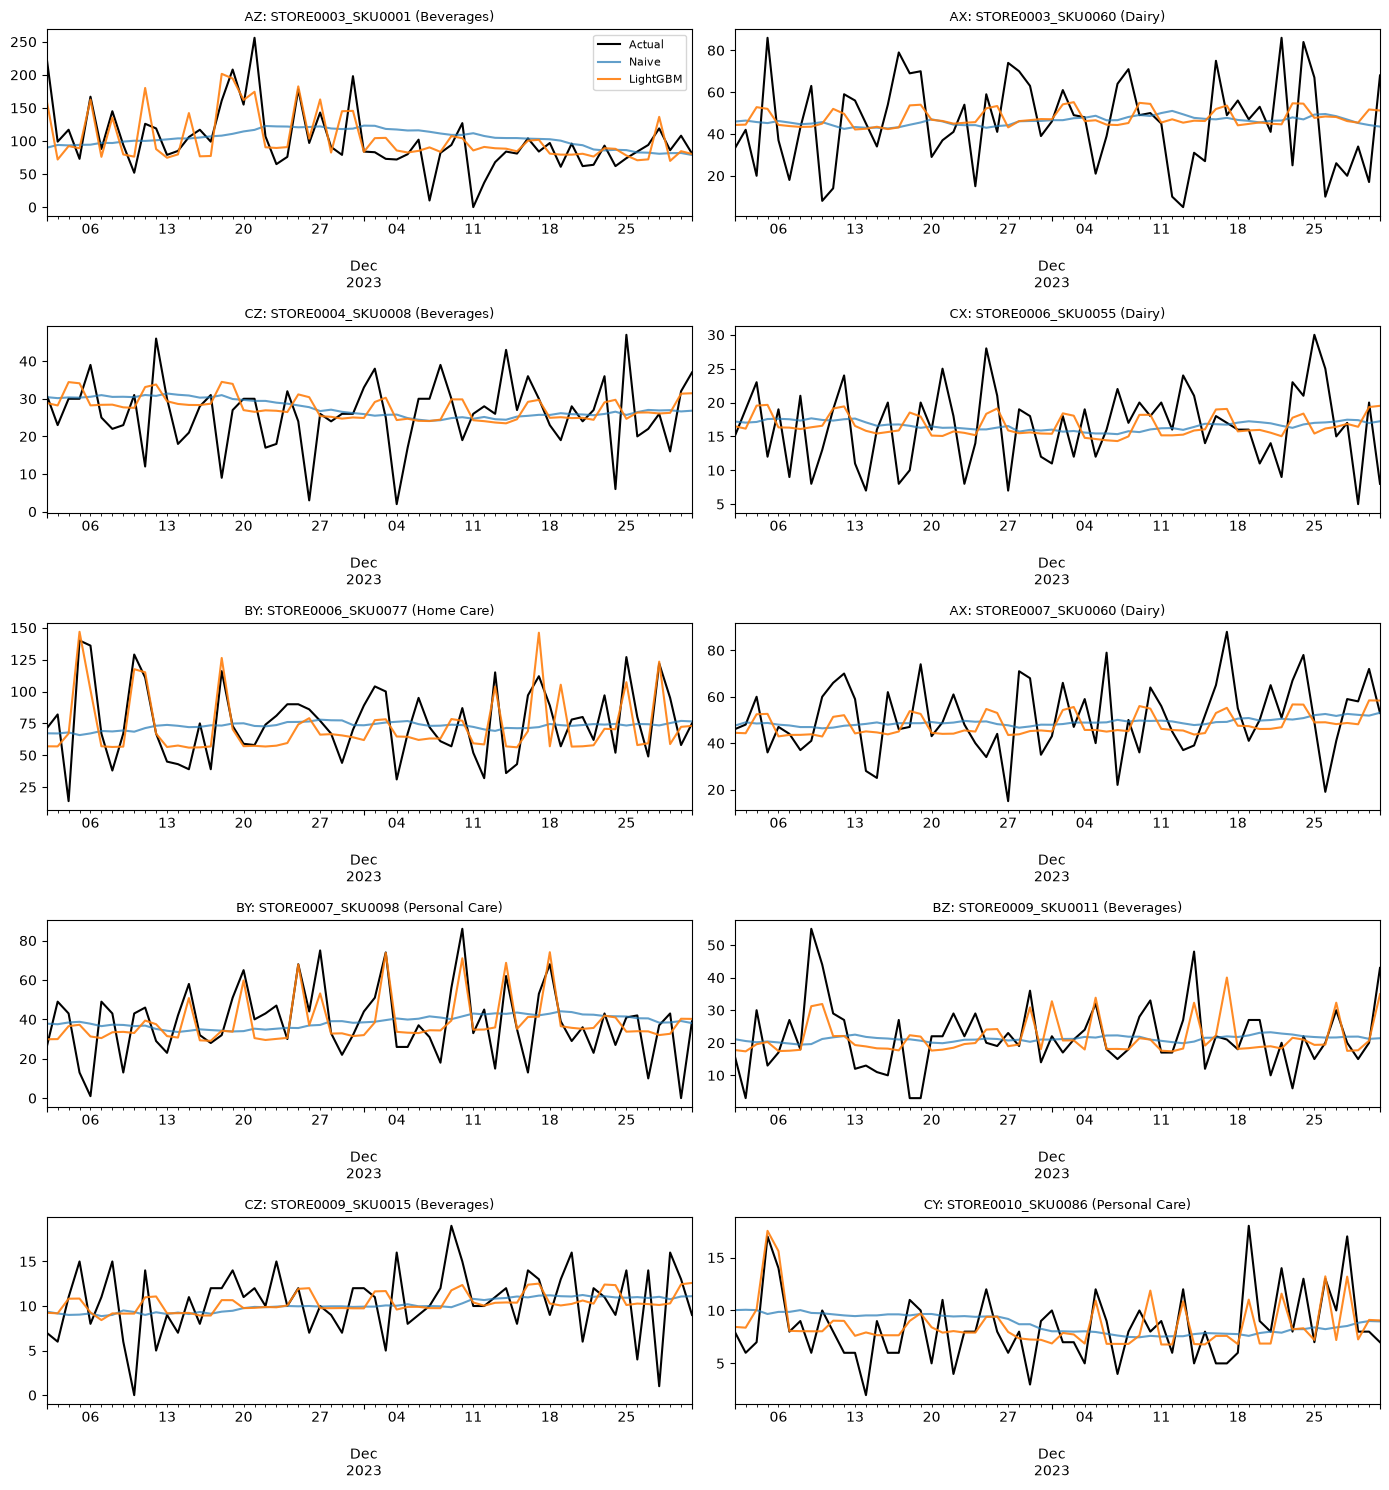

In [12]:
fig, axes = plt.subplots(5, 2, figsize=(14, 15), sharex=False)
for ax, (sid, g) in zip(axes.ravel(), sel.groupby("series_id")):
    g = g.sort_values("date").tail(60).set_index("date")
    g[target].plot(ax=ax, label="Actual", color="black", linewidth=1.5)
    g["naive"].plot(ax=ax, label="Naive", alpha=0.7)
    g["lightgbm"].plot(ax=ax, label="LightGBM", alpha=0.9)
    ax.set_title(f"{picked.loc[sid, 'segment']}: {sid} ({picked.loc[sid, 'category']})", fontsize=9)
    ax.set_xlabel("")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
savefig("ten_series_forecasts")
plt.show()

## 7. Stock-out prediction (classification)
**Task:** predict, before the day starts, whether a store-SKU will have a stock-out that day (`stock_out_flag = 1`). This is an imbalanced problem: only about 3% of days are stock-outs, so accuracy is misleading (always predicting "no stock-out" is 97% accurate and useless).

The metrics requested in the brief:
- **Precision:** of the days we flag, what share are real stock-outs?
- **Recall:** of all real stock-outs, what share did we flag?
- **F1:** the balance of the two.

Also reported: **PR-AUC** (average precision; compare with the base rate, which is what a random flag achieves) and ROC-AUC.

**Features** (all known before the day): the Phase 4/5 features (including promo, calendar, recent demand and recent stock-outs), plus yesterday's stock on hand, yesterday's lead time and **days of cover** (yesterday's stock divided by recent daily demand).

**Procedure:** train on the training period, pick the decision threshold that maximises F1 on the **validation** period, then score the **test** period once.

**How to read the result:** compare precision with the **base rate** and look at `flagged_%`. If the best-F1 threshold flags most days and precision is only about the base rate, the model has no real signal: "flag everything" scores about the same F1. A useful model has precision well above the base rate at a modest `flagged_%`, which the *top 5% of days* line shows directly (lift above 1.0x).

In [13]:
clf_feats = base_features + ["soh_lag1", "lt_lag1", "cover_days"]
tr, va, te = feats.loc[train_mask], feats.loc[valid_mask], feats.loc[test_mask]

pos_rate = tr["so_today"].mean()
print(f"Stock-out rate: train {pos_rate*100:.2f}% | validation {va['so_today'].mean()*100:.2f}% | test {te['so_today'].mean()*100:.2f}%")

clf = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.8, min_child_samples=100, importance_type="gain",
                         scale_pos_weight=(1 - pos_rate) / pos_rate,       # up-weight the rare class
                         random_state=SEED, n_jobs=-1, verbose=-1)
clf.fit(tr[clf_feats], tr["so_today"],
        eval_set=[(va[clf_feats], va["so_today"])], eval_metric="average_precision",
        callbacks=[lgb.early_stopping(50, verbose=False)])

p_val = clf.predict_proba(va[clf_feats])[:, 1]
prec, rec, thr = precision_recall_curve(va["so_today"], p_val)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1s)]
print(f"Validation: best F1 {f1s.max():.3f} at threshold {best_thr:.3f}")

Stock-out rate: train 3.02% | validation 3.01% | test 2.98%
Validation: best F1 0.058 at threshold 0.038


In [14]:
p_test = clf.predict_proba(te[clf_feats])[:, 1]
y_test = te["so_today"].values
pred = (p_test >= best_thr).astype(int)

def cls_row(name, y, yhat, score=None):
    return {"model": name,
            "precision": precision_score(y, yhat, zero_division=0),
            "recall": recall_score(y, yhat, zero_division=0),
            "F1": f1_score(y, yhat, zero_division=0),
            "PR_AUC": average_precision_score(y, score) if score is not None else np.nan,
            "ROC_AUC": roc_auc_score(y, score) if score is not None else np.nan,
            "flagged_%": yhat.mean() * 100}

base_rate = y_test.mean()
rows = [
    cls_row("LightGBM classifier (threshold from validation)", y_test, pred, p_test),
    cls_row("Rule: yesterday had a stock-out", y_test, te["stockout_lag1"].values.astype(int), te["stockout_lag1"].values),
    cls_row("Flag every day (recall = 1)", y_test, np.ones_like(y_test)),
]
res = pd.DataFrame(rows).set_index("model")
print(f"TEST SET (Jul-Dec 2023). Base rate (what random flagging achieves for precision): {base_rate*100:.2f}%")
print(res.round(3).to_string())

cm = confusion_matrix(y_test, pred)
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=["no stock-out", "stock-out"], columns=["pred no", "pred stock-out"]).to_string())

top = p_test >= np.quantile(p_test, 0.95)
print(f"\nTop 5% of days by predicted risk: precision {y_test[top].mean()*100:.2f}% (lift {y_test[top].mean()/base_rate:.2f}x vs base rate), "
      f"captures {y_test[top].sum()/y_test.sum()*100:.1f}% of all stock-outs")
res.to_csv("../reports/stockout_classification.csv")

TEST SET (Jul-Dec 2023). Base rate (what random flagging achieves for precision): 2.98%
                                                 precision  recall    F1  PR_AUC  ROC_AUC  flagged_%
model                                                                                               
LightGBM classifier (threshold from validation)      0.030   0.995 0.058   0.030    0.502     99.446
Rule: yesterday had a stock-out                      0.032   0.032 0.032   0.030    0.501      2.979
Flag every day (recall = 1)                          0.030   1.000 0.058     NaN      NaN    100.000

Confusion matrix (rows = actual, columns = predicted):
              pred no  pred stock-out
no stock-out      995          178244
stock-out          28            5469

Top 5% of days by predicted risk: precision 3.03% (lift 1.02x vs base rate), captures 7.0% of all stock-outs


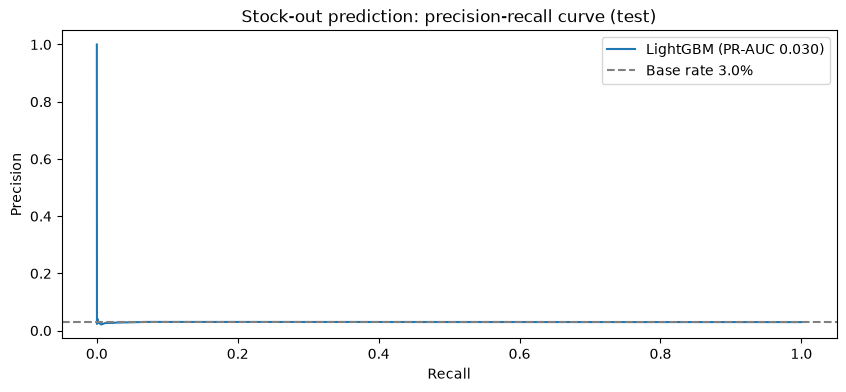

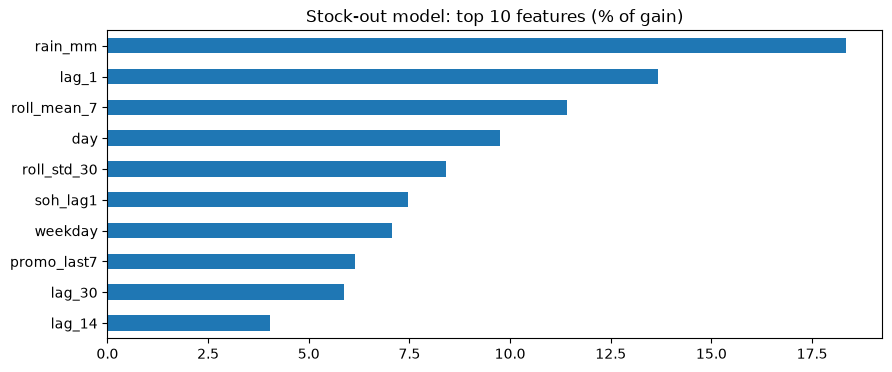

Stock-out rate (%) by days-of-cover decile (test):
cover_bin
(-0.001, 2.367]     3.030
(2.367, 3.06]       2.960
(3.06, 3.722]       2.950
(3.722, 4.46]       3.070
(4.46, 5.421]       3.070
(5.421, 6.778]      2.920
(6.778, 8.785]      2.850
(8.785, 11.842]     3.040
(11.842, 17.297]    2.930
(17.297, 119.636]   2.930


In [15]:
pr, rc, _ = precision_recall_curve(y_test, p_test)
plt.plot(rc, pr, label=f"LightGBM (PR-AUC {average_precision_score(y_test, p_test):.3f})")
plt.axhline(base_rate, color="grey", linestyle="--", label=f"Base rate {base_rate*100:.1f}%")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Stock-out prediction: precision-recall curve (test)")
plt.legend()
savefig("stockout_pr_curve")
plt.show()

imp = pd.Series(clf.feature_importances_, index=clf_feats)
(imp / imp.sum() * 100).sort_values().tail(10).plot(kind="barh", title="Stock-out model: top 10 features (% of gain)")
plt.show()

# Does low stock cover actually precede stock-outs?
te_c = te.assign(cover_bin=pd.qcut(te["cover_days"], 10, duplicates="drop"))
print("Stock-out rate (%) by days-of-cover decile (test):")
print((te_c.groupby("cover_bin", observed=True)["so_today"].mean() * 100).round(2).to_string())

## 8. Summary of findings
Stock-out prediction: The stock-out rate is stable at about 3% across train, validation and test (3.02%, 3.01%, 2.98%). On the test set (Jul–Dec 2023), LightGBM reached a PR-AUC of 0.030, equal to the base rate, and a ROC-AUC of 0.502. Its validation-tuned threshold flagged 99.4% of days, giving precision 0.030 and recall 0.995, which is identical to flagging every day (F1 0.058). The top 5% of days by predicted risk showed a lift of only 1.02x. The “yesterday had a stock-out” rule (precision 0.032) and days-of-cover (stock-out rate about 3% in every decile) also had no predictive value. The model is not operationally usable and is close to chance. This suggests stock-outs in this dataset are largely random rather than driven by demand history, stock cover, promotions or weather.